# 05 — Controlling for world commodity prices

Next step 4b in `CONTRIBUTING.md` (decision D22). D20 flagged coffee and confectionery in 2025: both rose during world price shocks that Canadian donor series cannot reproduce.

- World prices: World Bank Commodity Price Data, "Pink Sheet", monthly [S15], converted to CAD with the Bank of Canada rate (D15).
- Mapping CPI series → commodity: `data/reference/commodity_map.csv`.
- For each mapped treated series, elasticities to the world price (lags 0–11 months, in four blocks) are estimated on **12-month log changes** over all months before the tariff since 2005; the implied commodity component is removed from the series, then the synthetic control and the pass-through DiD (D21) are run again.
- Code: `src/fetch_commodities.py`, `src/causal/commodity.py`.

In [1]:
import sys
from pathlib import Path
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(root / "src"), str(root / "src" / "causal")]
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import synth as S, commodity as C, exposure as E
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 50)

roles = pd.read_csv(root / "data/processed/treatment_roles.csv")
cat = pd.read_csv(root / "data/processed/cpi_food_catalog.csv")
parent = dict(zip(cat["product"], cat["parent"]))
x = pd.read_csv(root / "data/processed/exposure.csv")
wide = S.cpi_wide()
COMMODITY_HEAVY = ["Roasted or ground coffee (2013=100)", "Confectionery"]

def groups(ev):
    u = roles[(roles.event_id == ev) & roles.usable]
    return (u[u.role == "treated"]["product"].tolist(),
            S.finest(u[u.role == "control"]["product"].tolist(), parent))

## 1. Elasticities and commodity-adjusted synthetic-control effects

In [2]:
tabs, pts, Ys = [], [], {}
for ev, ep in S.EPISODES.items():
    tr, don = groups(ev)
    Y = S.outcome(wide, ep, tr + don, "main").dropna(axis=1)
    w = ep.windows(wide.index.max()); xe = x[x.event_id == ev]
    for lag_label, blocks in [("lags 0-11", C.LAG_BLOCKS), ("lags 0-17", C.LONG_LAG_BLOCKS)]:
        tab, Yadj = C.adjust(wide, Y, ep, tr, blocks)
        Ys[(ev, lag_label)] = Yadj
        if lag_label == "lags 0-11":
            res0, _ = S.run_episode(wide, ep, tr, don, [], Y=Y)
            res1, _ = S.run_episode(wide, ep, tr, don, [], Y=Yadj)
            m = res0[["series", "effect_during", "p_value"]].merge(
                res1[["series", "effect_during", "effect_after", "p_value"]], on="series", suffixes=("_raw", "_adj"))
            tabs.append(tab.merge(m, on="series"))
        for sample, xs in [("all treated", xe), ("without coffee and confectionery", xe[~xe.series.isin(COMMODITY_HEAVY)])]:
            if ev == "CA2018" and sample != "all treated":
                continue
            pts.append({"event_id": ev, "outcome": f"commodity-adjusted ({lag_label})", "sample": sample,
                        **E.intensity_did(Yadj, xs, don, ep.first_month, ep.last_month, w["pre"][0])})
    for sample, xs in [("all treated", xe), ("without coffee and confectionery", xe[~xe.series.isin(COMMODITY_HEAVY)])]:
        if ev == "CA2018" and sample != "all treated":
            continue
        pts.append({"event_id": ev, "outcome": "raw (D21)", "sample": sample,
                    **E.intensity_did(Y, xs, don, ep.first_month, ep.last_month, w["pre"][0])})
adj = pd.concat(tabs)
adj.to_csv(root / "data/processed/commodity_adjustment.csv", index=False)
adj[["event_id", "series", "commodity", "elasticity", "r2", "n_obs", "commodity_part_during",
     "effect_during_raw", "p_value_raw", "effect_during_adj", "p_value_adj"]].round(3)

,event_id,series,commodity,elasticity,r2,n_obs,commodity_part_during,effect_during_raw,p_value_raw,effect_during_adj,p_value_adj
0,CA2018,Fruit juices,Orange,-0.079,0.163,113,-0.161,-3.135,0.396,-3.922,0.283
1,CA2018,Confectionery,Cocoa,0.024,0.219,113,-0.494,-1.798,0.321,-1.513,0.132
2,CA2018,Roasted or ground coffee (2013=100),"Coffee, Arabica",0.014,0.793,54,0.146,-2.107,0.509,-0.907,0.698
0,CA2025,Rice and rice-based mixes,"Rice, Thai 5%",0.188,0.327,193,-1.350,-2.124,0.522,2.144,0.565
1,CA2025,Dry or fresh pasta (2013=100),"Wheat, US HRW",0.237,0.268,134,-1.000,-0.176,0.957,-0.545,0.957
2,CA2025,Flour and flour-based mixes,"Wheat, US HRW",0.191,0.453,193,-1.522,-7.031,0.130,-2.089,0.696
3,CA2025,Oranges,Orange,0.008,0.010,193,0.397,6.558,0.565,6.208,0.696
4,CA2025,Fruit juices,Orange,0.089,0.210,193,5.709,5.810,0.130,3.662,0.261
5,CA2025,Sugar and syrup,"Sugar, world",0.271,0.437,193,3.251,-0.843,0.957,3.196,0.739
6,CA2025,Confectionery,Cocoa,0.013,0.021,193,1.303,3.856,0.087,3.172,0.304


## 2. Pass-through before and after the commodity adjustment

In [3]:
pt = pd.DataFrame(pts).sort_values(["event_id", "sample", "outcome"])
pt.to_csv(root / "data/processed/pass_through_commodity.csv", index=False)
pt[["event_id", "sample", "outcome", "pass_through", "lo", "hi", "p", "n_treated"]].round(3)

,event_id,sample,outcome,pass_through,lo,hi,p,n_treated
0,CA2018,all treated,commodity-adjusted (lags 0-11),-0.941,-2.439,0.558,0.219,10
1,CA2018,all treated,commodity-adjusted (lags 0-17),-0.863,-2.331,0.604,0.249,10
2,CA2018,all treated,raw (D21),-0.957,-2.450,0.536,0.209,10
3,CA2025,all treated,commodity-adjusted (lags 0-11),0.693,0.010,1.376,0.047,22
5,CA2025,all treated,commodity-adjusted (lags 0-17),0.616,0.034,1.199,0.038,22
7,CA2025,all treated,raw (D21),0.833,-0.112,1.779,0.084,22
4,CA2025,without coffee and confectionery,commodity-adjusted (lags 0-11),0.392,-0.074,0.858,0.099,20
6,CA2025,without coffee and confectionery,commodity-adjusted (lags 0-17),0.438,-0.049,0.925,0.078,20
8,CA2025,without coffee and confectionery,raw (D21),0.347,-0.121,0.814,0.146,20


## 3. Coffee in 2025: Canadian CPI vs world arabica price (CAD)

Both indexed to 100 in January 2023, one axis (log scale). Tariff months shaded.

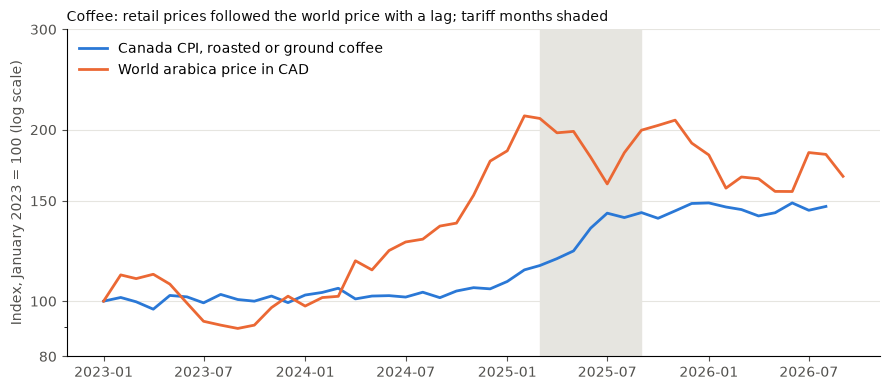

In [4]:
prices = C.world_prices_cad()
base = pd.Period("2023-01", "M")
cpi = wide["Roasted or ground coffee (2013=100)"].loc[base:]
arab = np.exp(prices["Coffee, Arabica"]).loc[base:]
ep = S.EPISODES["CA2025"]
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e0"
fig, ax = plt.subplots(figsize=(9, 4))
t = cpi.index.to_timestamp()
ax.axvspan(ep.first_month.to_timestamp(), (ep.last_month + 1).to_timestamp(), color=GRID, zorder=0)
ax.plot(t, 100 * cpi / cpi.loc[base], color=BLUE, lw=2, label="Canada CPI, roasted or ground coffee")
ax.plot(arab.index.to_timestamp(), 100 * arab / arab.loc[base], color=ORANGE, lw=2, label="World arabica price in CAD")
ax.set_yscale("log")
ax.set_yticks([80, 100, 150, 200, 300]); ax.set_yticklabels(["80", "100", "150", "200", "300"])
ax.set_ylabel("Index, January 2023 = 100 (log scale)", color=MUTED)
ax.tick_params(colors=MUTED)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.grid(axis="y", color=GRID, lw=0.8)
ax.legend(frameon=False, loc="upper left")
ax.set_title("Coffee: retail prices followed the world price with a lag; tariff months shaded", color=INK, fontsize=10, loc="left")
plt.tight_layout(); plt.show()

## 4. Findings

Written up in D22 (decision log).